# Kinematic slip on a Slab2 slab, meshed by gmsh, step 2: the Bayesian inversion with AlTar

[Step 1](step1_mesh.ipynb) made kinematic_mesh's synthetic on a patch of Slab2 under Ecuador, meshed by gmsh. This notebook runs the cascaded inversion: the static data first, then the waveforms, with the slips, the rise times, a rupture velocity for each group of patches and the hypocenter.

The slips are sampled as a magnitude and a rake per patch, the ensemble's `polar` (see the guide's [Kinematic models](https://altar2.readthedocs.io/en/latest/guide/Kinematic.html)): the magnitude U(0, 15) m, the rake N(0, 20°) from the convergence. kinematic_mesh samples the two components instead, along the convergence U(-1, 15) m and across it N(0, 0.5) m; the same inversion with those priors, on the same data, is in `components/`, for comparison.

The sampler is the one the guide recommends: HMC walks until the chains decorrelate, a mass matrix pooled over 16 β steps, and 160 more walks at β = 1, with 512 chains, about an hour on one GPU. The cells that run AlTar skip their run if its results are in `results/` already.

In [1]:
import os
import h5py
import numpy as np
import matplotlib
import matplotlib.pyplot as plt

with h5py.File('input/mesh.h5') as h5:
    V, F, uv = (np.asarray(h5[k]) for k in ['vertices', 'faces', 'uv'])
    groups = np.asarray(h5['groups/velocity'])
with h5py.File('input/synthetic.h5') as h5:
    true = {k: np.asarray(v) for k, v in h5['true'].items()}
    mu, area, dt = np.asarray(h5['mu']), np.asarray(h5['area']), float(h5['dt'][()])
true['magnitude'] = np.hypot(true['across'], true['parallel'])
true['rake'] = np.degrees(np.arctan2(true['across'], true['parallel']))

def load(results):
    # the posterior samples, with the slips as components and as a magnitude and a rake, whichever were sampled
    with h5py.File(f'{results}/step_final.h5') as h5:
        P = h5['ParameterSets']
        get = lambda s: np.asarray(P[f'{s}_physical'] if f'{s}_physical' in P else P[s], dtype=float)
        names = [s for s in ['magnitude', 'rake', 'across', 'parallel', 'risetime', 'rupturevelocity', 'hypo_strike', 'hypo_dip']
                 if s in P or f'{s}_physical' in P]
        post = {s: get(s) for s in names}
    if 'magnitude' in post:
        post['parallel'] = post['magnitude'] * np.cos(np.radians(post['rake']))
        post['across'] = post['magnitude'] * np.sin(np.radians(post['rake']))
    else:
        post['magnitude'] = np.hypot(post['across'], post['parallel'])
        post['rake'] = np.degrees(np.arctan2(post['across'], post['parallel']))
    post['hypocenter'] = np.column_stack([post.pop('hypo_strike')[:, 0], post.pop('hypo_dip')[:, 0]])
    return post

def summary(run):
    # the beta steps of a run, and its acceptance rates, from its BetaStatistics.txt
    stats = np.loadtxt(f'{run}/BetaStatistics.txt', delimiter=',', skiprows=1)[1:]
    acceptance = stats[:, 3] / stats[:, 3:].sum(1)
    print(f"{run}: {int(stats[-1, 0])} beta steps to beta = {stats[-1, 1]:g}; acceptance rate {acceptance.min():.2f} to {acceptance.max():.2f}")

## The static inversion

The slips from the GPS and the line of sight alone. A static model takes polar slips as the single model of an ensemble:

In [2]:
print(open('static.pfg').read())

; step 2, the static inversion: the slips from the static data alone, gps and line of sight, as a
; magnitude U(0, 15) m and a rake N(0, 20) degrees from the convergence, per patch
slipmodel:
    model = altar.models.ensemble
    model:
        case = input
        patches = 132
        polar = [magnitude, rake, parallel, across]
        psets_list = [magnitude, rake]
        psets:
            magnitude = contiguous
            rake = contiguous
            magnitude:
                count = {slipmodel.model.patches}
                prior = uniform
                prior.support = (0.0, 15.0)
                prior.reparameterize = True
            rake:
                count = {slipmodel.model.patches}
                prior = gaussian
                prior.mean = 0
                prior.sigma = 20
        models:
            static = altar.models.seismic.static
            static:
                case = {slipmodel.model.case}
                patches = {slipmodel.model.patches}
        

In [3]:
if not os.path.exists('results/static/step_final.h5'):
    !slipmodel.plexus sample --config=static.pfg > static.log 2>&1
summary('results/static')

results/static: 82 beta steps to beta = 1; acceptance rate 0.70 to 0.73


## The cascaded inversion

The ensemble of the static model, at β = 1 throughout, and the kinematic model on triangles, annealed; the magnitudes and rakes start from the static posterior. The hypocenter's prior is centered 5 km from the true one, as a catalog's might be.

In [4]:
print(open('cascaded.pfg').read())

; step 3, the cascaded inversion: the static data at beta = 1 throughout, the waveforms annealed;
; the slips, a magnitude and a rake per patch, start from the static posterior; a rise time per
; patch, a rupture velocity per group of patches, and the hypocenter, with a prior 5 km off the
; true one, as a catalog's might be
slipmodel:
    model = altar.models.ensemble
    model:
        case = input
        patches = 132
        ; the slips as a magnitude and a rake from the convergence; the models get the two components
        polar = [magnitude, rake, parallel, across]
        psets_list = [magnitude, rake, risetime, rupturevelocity, hypo_strike, hypo_dip]
        psets:
            magnitude = contiguous
            rake = contiguous
            risetime = contiguous
            rupturevelocity = contiguous
            hypo_strike = contiguous
            hypo_dip = contiguous
            magnitude:
                count = {slipmodel.model.patches}
                prep = preset
   

In [5]:
if not os.path.exists('results/cascaded/step_final.h5'):
    !slipmodel.plexus sample --config=cascaded.pfg > cascaded.log 2>&1
summary('results/cascaded')
summary('components/results/cascaded')

results/cascaded: 61 beta steps to beta = 1; acceptance rate 0.45 to 0.72
components/results/cascaded: 71 beta steps to beta = 1; acceptance rate 0.40 to 0.71


## The fit to the data

The `forward` action runs the models on the posterior mean and on the posterior samples, each on its own data; its output keeps the predictions and the slip history of the mean model.

In [6]:
if not os.path.exists('results/cascaded/forward.h5'):
    !slipmodel.plexus forward --config=cascaded.pfg --slipmodel.forward.theta=results/cascaded/step_final.h5 \
        --slipmodel.forward.output=results/cascaded/forward.h5 --slipmodel.forward.samples=2000 > forward.log 2>&1
runs = {'polar': 'results/cascaded', 'components': 'components/results/cascaded'}
for label, path in runs.items():
    with h5py.File(f'{path}/forward.h5') as h5:
        fits = []
        for model in ['kinematic', 'static']:
            d, p = np.asarray(h5[f'{model}/data/observed']), np.asarray(h5[f'{model}/data/mean_model'])
            chi2 = float(h5[f'{model}/fit/mean_model/chi2'][()]) / float(h5[f'{model}/fit/observations'][()])
            fits.append(f"{model} chi-square per datum {chi2:.2f}, variance reduction {1 - ((d - p) ** 2).sum() / (d ** 2).sum():.4f}")
    print(f"{label}: " + '; '.join(fits))

polar: kinematic chi-square per datum 0.99, variance reduction 0.9914; static chi-square per datum 0.89, variance reduction 0.9991
components: kinematic chi-square per datum 1.01, variance reduction 0.9913; static chi-square per datum 0.80, variance reduction 0.9992


## The posterior against the truth

The errors of the posterior mean against the truth, patch by patch and weighted by the areas of the patches, which differ several fold on the graded mesh; the share of the true values within the 68% interval of their posterior; the moment magnitude, from the magnitudes of the slips; the rupture velocities and the hypocenter.

In [7]:
posts = {label: load(path) for label, path in runs.items()}
magnitude = lambda slip: 2 / 3 * (np.log10((mu * area * 1e6 * slip).sum(-1)) - 9.1)
w = area / area.sum()
share = np.bincount(groups, weights=mu * area * true['magnitude']) / (mu * area * true['magnitude']).sum()
big = share > 0.05
rows = []
for label, p in posts.items():
    mean = {s: v.mean(0) for s, v in p.items()}
    lo, hi = np.percentile(p['parallel'], [16, 84], axis=0)
    Mw = magnitude(p['magnitude'])
    verr = mean['rupturevelocity'] - true['rupturevelocity']
    rows.append((np.corrcoef(mean['parallel'], true['parallel'])[0, 1],
                 np.sqrt(((mean['parallel'] - true['parallel']) ** 2).mean()), np.sqrt((w * (mean['parallel'] - true['parallel']) ** 2).sum()),
                 ((lo <= true['parallel']) & (true['parallel'] <= hi)).mean(), np.median(p['parallel'].std(0)),
                 np.sqrt(((mean['across'] - true['across']) ** 2).mean()),
                 np.sqrt((verr ** 2).mean()), np.sqrt((verr[big] ** 2).mean()),
                 f"{Mw.mean():.3f} ± {Mw.std():.3f}", magnitude(true['magnitude']),
                 f"{mean['hypocenter'][0]:.1f} ± {p['hypocenter'][:, 0].std():.1f}, {mean['hypocenter'][1]:.1f} ± {p['hypocenter'][:, 1].std():.1f}"))
labels = ['slip along: correlation', 'rms error (m)', 'rms error, area weighted (m)', 'within 68%', 'median sd (m)',
          'slip across: rms error (m)', 'velocities: rms error (km/s)', '  groups > 5% of the moment', 'Mw', 'true Mw',
          'hypocenter (true 125.0, 55.0)']
formats = ['{:.3f}', '{:.3f}', '{:.3f}', '{:.0%}', '{:.3f}', '{:.3f}', '{:.2f}', '{:.2f}', '{}', '{:.3f}', '{}']
print(f"{'':32s}" + ''.join(f"{label:>24s}" for label in posts))
for k, (label, fmt) in enumerate(zip(labels, formats)):
    print(f"{label:32s}" + ''.join(f"{fmt.format(r[k]):>24s}" for r in rows))

                                                   polar              components
slip along: correlation                            0.990                   0.974
rms error (m)                                      0.159                   0.260
rms error, area weighted (m)                       0.148                   0.240
within 68%                                           80%                     80%
median sd (m)                                      0.176                   0.387
slip across: rms error (m)                         0.076                   0.126
velocities: rms error (km/s)                        0.32                    0.44
  groups > 5% of the moment                         0.19                    0.23
Mw                                         7.953 ± 0.002           8.004 ± 0.007
true Mw                                            7.946                   7.946
hypocenter (true 125.0, 55.0)    124.5 ± 1.1, 54.3 ± 1.4 124.9 ± 1.2, 54.3 ± 1.7


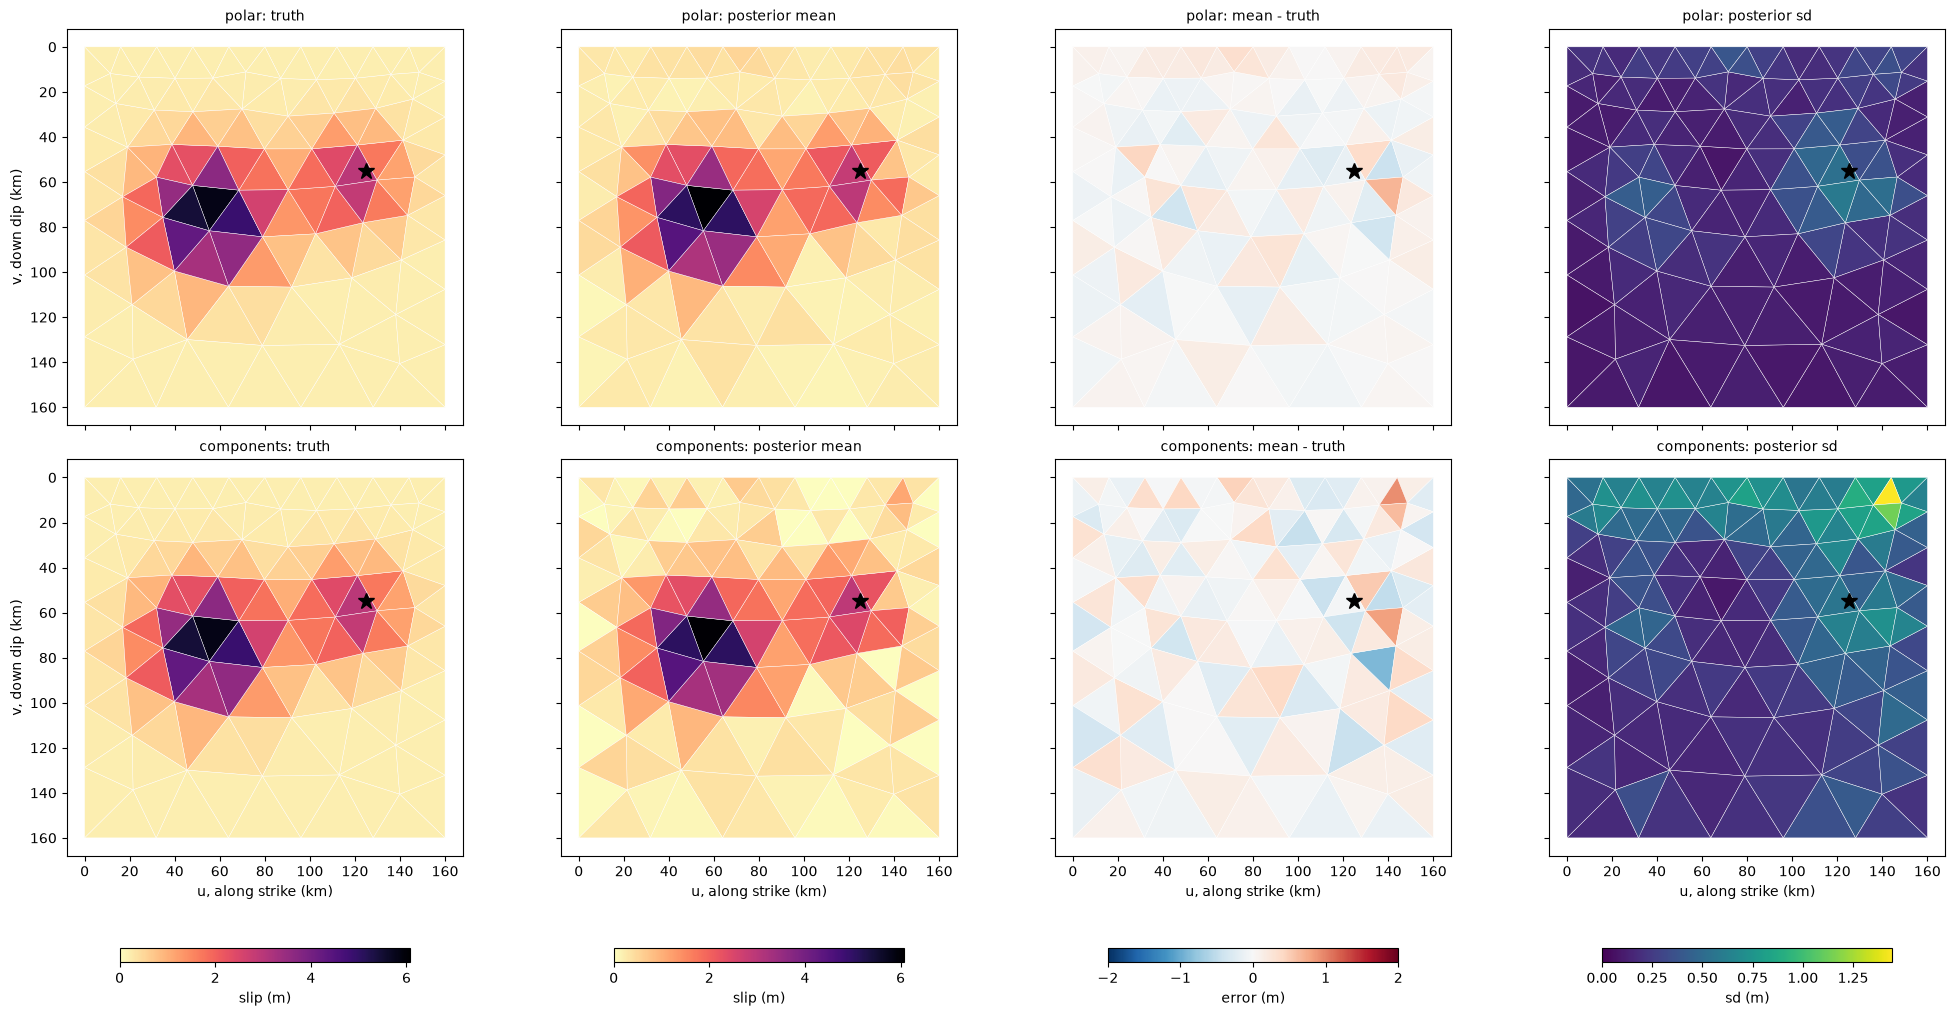

In [8]:
# the slip along the convergence: the truth, and the posterior mean, its error and sd, with each prior
fig, axes = plt.subplots(2, 4, figsize=(20, 10), sharex=True, sharey=True, layout='constrained')
top = max(true['parallel'].max(), *(p['parallel'].mean(0).max() for p in posts.values()))
sdmax = max(p['parallel'].std(0).max() for p in posts.values())
for row, (label, p) in enumerate(posts.items()):
    panels = [(true['parallel'], 'truth', 'magma_r', 0, top), (p['parallel'].mean(0), 'posterior mean', 'magma_r', 0, top),
              (p['parallel'].mean(0) - true['parallel'], 'mean - truth', 'RdBu_r', -2, 2), (p['parallel'].std(0), 'posterior sd', 'viridis', 0, sdmax)]
    for col, (values, title, cmap, lo, hi) in enumerate(panels):
        ax = axes[row, col]
        pc = ax.tripcolor(uv[:, 0], uv[:, 1], F, facecolors=values, cmap=cmap, vmin=lo, vmax=hi, edgecolors='w', lw=0.3)
        ax.plot(*true['hypocenter'], 'k*', ms=12)
        ax.set_title(f'{label}: {title}', fontsize=10); ax.set_aspect('equal')
        if row == 1:
            ax.set_xlabel('u, along strike (km)')
            fig.colorbar(pc, ax=axes[:, col], shrink=0.6, orientation='horizontal', label=['slip (m)', 'slip (m)', 'error (m)', 'sd (m)'][col])
    axes[row, 0].set_ylabel('v, down dip (km)')
axes[0, 0].invert_yaxis()
plt.show()

With independent components, every patch can slip across the convergence by about 0.5 m and slip back along it by up to 1 m, however little it slips: in the patches the data barely resolve, that spread adds to the magnitudes, and the moment from them comes out too large. With polar slips, the spread across the convergence scales with the magnitude, and the magnitude can't go below zero. The rakes: their posterior sd against the magnitude of the slip, and the error of their mean:

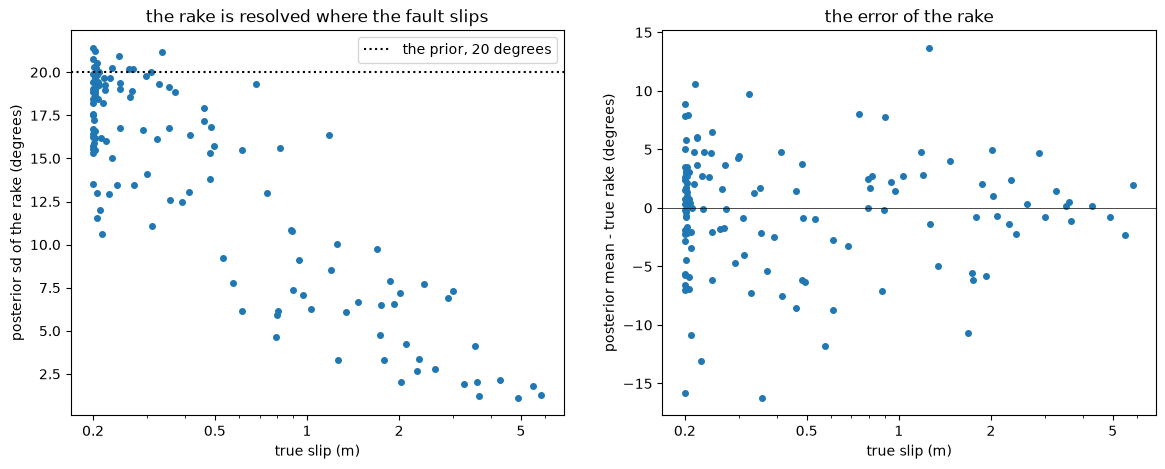

In [9]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
p = posts['polar']
ax1.semilogx(true['magnitude'], p['rake'].std(0), 'o', ms=4)
ax1.axhline(20, color='k', ls=':', label='the prior, 20 degrees')
ax1.set_xlabel('true slip (m)'); ax1.set_ylabel('posterior sd of the rake (degrees)'); ax1.legend()
ax1.set_title('the rake is resolved where the fault slips')
ax2.semilogx(true['magnitude'], p['rake'].mean(0) - true['rake'], 'o', ms=4)
ax2.axhline(0, color='k', lw=0.5)
ax2.set_xlabel('true slip (m)'); ax2.set_ylabel('posterior mean - true rake (degrees)')
ax2.set_title('the error of the rake')
for ax in (ax1, ax2):
    ax.set_xticks([0.2, 0.5, 1, 2, 5])
    ax.xaxis.set_major_formatter(matplotlib.ticker.FormatStrFormatter('%g'))
    ax.xaxis.set_minor_formatter(matplotlib.ticker.NullFormatter())
plt.show()

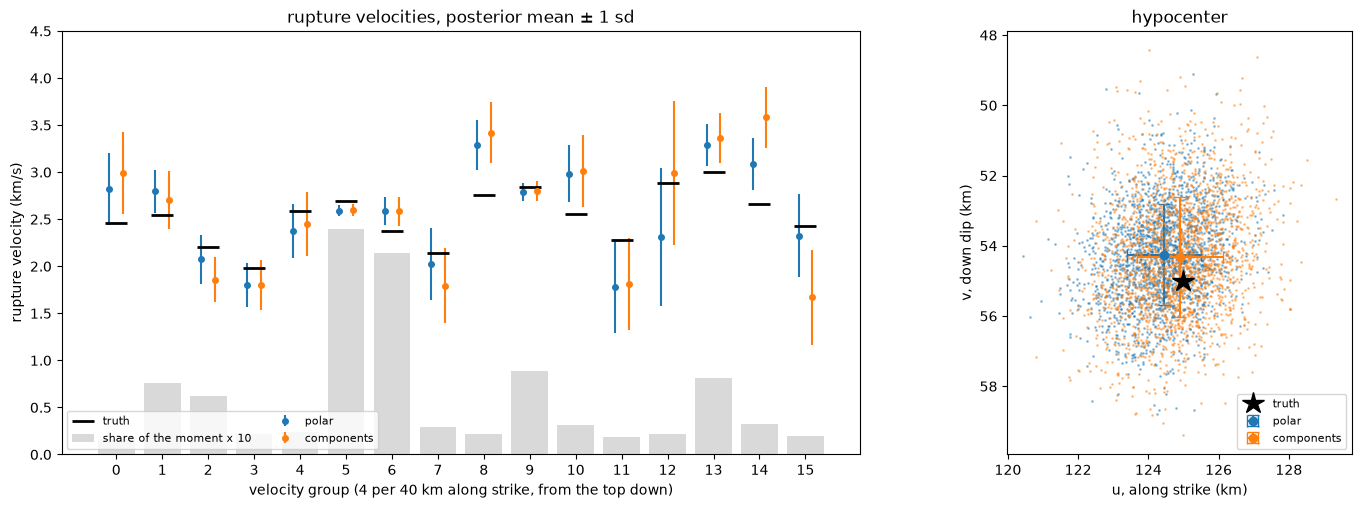

In [10]:
# the rupture velocities, with the moment of each group, and the hypocenter
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(17, 5.5), gridspec_kw={'width_ratios': [2, 1]})
order = np.arange(16)
ax1.bar(order, 10 * share, color='0.85', width=0.8, label='share of the moment x 10')
for k, (label, p) in enumerate(posts.items()):
    v = p['rupturevelocity']
    ax1.errorbar(order + (k - 0.5) * 0.3, v.mean(0), yerr=v.std(0), fmt='o', ms=4, color=f'C{k}', label=label)
    h = p['hypocenter']
    ax2.plot(*h[::4].T, '.', ms=2, alpha=0.4, color=f'C{k}')
    ax2.errorbar(*h.mean(0), xerr=h[:, 0].std(), yerr=h[:, 1].std(), fmt='o', color=f'C{k}', capsize=4, label=label)
ax1.plot(order, true['rupturevelocity'], 'k_', ms=16, mew=2, label='truth')
ax1.set_xticks(order); ax1.set_ylim(0, 4.5)
ax1.set_xlabel('velocity group (4 per 40 km along strike, from the top down)'); ax1.set_ylabel('rupture velocity (km/s)')
ax1.set_title('rupture velocities, posterior mean ± 1 sd'); ax1.legend(fontsize=8, loc='lower left', ncol=2)
ax2.plot(*true['hypocenter'], 'k*', ms=16, label='truth')
ax2.set_aspect('equal'); ax2.invert_yaxis(); ax2.legend(fontsize=8)
ax2.set_xlabel('u, along strike (km)'); ax2.set_ylabel('v, down dip (km)'); ax2.set_title('hypocenter')
plt.show()

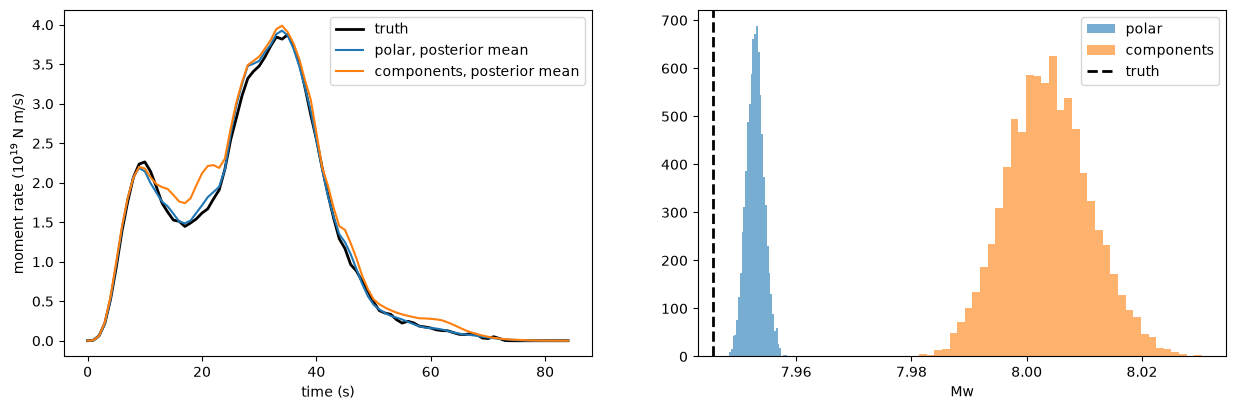

In [11]:
# the moment rate of the posterior mean, and the moment magnitude
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 4.5))
rate = lambda Mb: (mu * area * 1e6 * np.hypot(Mb[:, 0], Mb[:, 1])).sum(1) / dt / 1e19
tk = np.arange(true['Mb'].shape[0]) * dt
ax1.plot(tk, rate(true['Mb']), 'k', lw=2, label='truth')
for k, (label, path) in enumerate(runs.items()):
    with h5py.File(f'{path}/forward.h5') as h5:
        Mb = np.asarray(h5['kinematic/Mb/mean']).reshape(true['Mb'].shape)
    ax1.plot(tk, rate(Mb), color=f'C{k}', label=f'{label}, posterior mean')
    ax2.hist(magnitude(posts[label]['magnitude']), bins=40, color=f'C{k}', alpha=0.6, label=label)
ax2.axvline(magnitude(true['magnitude']), color='k', ls='--', lw=2, label='truth')
ax1.set_xlabel('time (s)'); ax1.set_ylabel('moment rate (10$^{19}$ N m/s)'); ax1.legend()
ax2.set_xlabel('Mw'); ax2.legend()
plt.show()

## Summary

- Slab2 gives the geometry of the interface. gmsh meshes it in surface coordinates made from cross-sections of the slab, and the vertices go onto it. Where the trench bends, as here, edges on the slab differ from those in the surface coordinates by up to 5.5%; the rupture times are computed in three dimensions, so this only shifts where the hypocenter, given in surface coordinates, lands, slightly.
- With polar slips, the posterior is closer to the truth on every measure: the slip errors about 40% smaller, along and across the convergence; the rupture velocities closer, 0.32 against 0.44 km/s; and the moment magnitude 7.953, against a true 7.946, where independent components give 8.004. The run takes half as long, 33 minutes and 61 β steps against 67 and 71.
- The rakes are resolved where the fault slips more than about 1 m, with posterior sds of 1° to 10°; where it barely slips, they keep their prior's 20°.
- Both posteriors are somewhat overconfident: 80% of the slips lie within their 68% intervals, but the moment magnitude's sd, 0.002, does not cover its remaining error of 0.007, and the rupture velocities of some groups that release little moment are off by more than their sds, e.g. groups 8, 13 and 14, too fast with either prior. Those velocities are best not trusted.
- The mesh matters less than the prior: the same inversion with independent components on the regular mesh of step 1 recovers the slips and velocities about as well as on the gmsh one (slip errors weighted by area 0.33 against 0.24 m, velocities 0.45 against 0.44 km/s). gmsh is the choice for real faults for their outlines and junctions, and a size graded with the resolution of the data, rather than for accuracy on a simple patch.
